# Assignment 3 — Module 3: Evolutionary and Swarm Optimization


## Practical 2: Fitness Function for Evaluating Individuals

### Aim
To define and calculate a simple fitness function for evaluating individuals in a Genetic Algorithm using Python.

### Theory
The **fitness function** measures how good an individual is. For this practical we minimize the **Sphere function**, a standard benchmark:

$$f(\mathbf{x}) = \sum_{i=1}^{n} x_i^2, \qquad \text{global minimum } f(\mathbf{0}) = 0$$

Because GA selection favours *higher* fitness, we convert the objective to a fitness value with

$$\text{fitness}(\mathbf{x}) = \frac{1}{1 + f(\mathbf{x})}$$

so that smaller objective values give larger fitness (maximum fitness $=1$ at the optimum).

### Objective and fitness functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sphere(x):
    # Objective to minimize
    return np.sum(x**2)

def fitness(x):
    # Higher fitness = better individual
    return 1.0 / (1.0 + sphere(x))

### Evaluating a small population

In [2]:
rng = np.random.default_rng(0)
pop = rng.uniform(-5.12, 5.12, size=(8, 3))   # 8 individuals, 3 variables each

results = []
for i, ind in enumerate(pop):
    results.append((i, sphere(ind), fitness(ind)))
    print(f"Ind {i}: x = {np.round(ind, 3)}  f(x) = {sphere(ind):8.4f}  fitness = {fitness(ind):.4f}")

best = max(results, key=lambda r: r[2])
print(f"\nBest individual: index {best[0]} with fitness {best[2]:.4f}")

Ind 0: x = [ 1.402 -2.357 -4.7  ]  f(x) =  29.6183  fitness = 0.0327
Ind 1: x = [-4.951  3.208  4.227]  f(x) =  52.6648  fitness = 0.0186
Ind 2: x = [1.092 2.35  0.447]  f(x) =   6.9146  fitness = 0.1263
Ind 3: x = [ 4.455  3.234 -5.092]  f(x) =  56.2373  fitness = 0.0175
Ind 4: x = [ 3.66  -4.776  2.352]  f(x) =  41.7356  fitness = 0.0234
Ind 5: x = [-3.321  3.719  0.425]  f(x) =  25.0418  fitness = 0.0384
Ind 6: x = [-2.051 -0.792 -4.83 ]  f(x) =  28.1621  fitness = 0.0343
Ind 7: x = [-3.847  1.747  1.507]  f(x) =  20.1264  fitness = 0.0473

Best individual: index 2 with fitness 0.1263


### Checking the optimum and visualizing fitness landscape

Fitness at optimum [0,0,0]: 1.0
Fitness at [1,1,1]        : 0.25


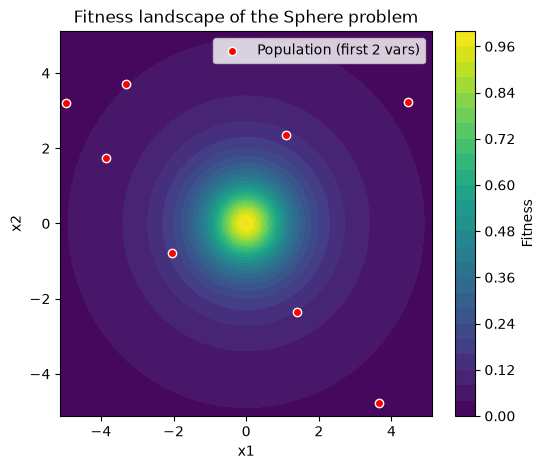

In [3]:
# Sanity check: the optimum should have the highest fitness
print("Fitness at optimum [0,0,0]:", fitness(np.zeros(3)))
print("Fitness at [1,1,1]        :", round(fitness(np.ones(3)), 4))

# 2-D landscape for visualization
xs = np.linspace(-5.12, 5.12, 200)
X1, X2 = np.meshgrid(xs, xs)
F = 1.0 / (1.0 + X1**2 + X2**2)

plt.figure(figsize=(6, 5))
cs = plt.contourf(X1, X2, F, levels=30, cmap='viridis')
plt.colorbar(cs, label='Fitness')
plt.scatter(pop[:, 0], pop[:, 1], c='red', edgecolors='white', label='Population (first 2 vars)')
plt.title('Fitness landscape of the Sphere problem')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend()
plt.show()

### Observation
- The objective $f(\mathbf{x})$ is smallest near the origin, and the fitness $1/(1+f)$ is largest there, so the best individual is the one closest to $\mathbf{0}$.
- The fitness landscape plot shows a single bright peak at the origin, confirming the function has one global optimum.

### Conclusion
Defined a fitness function for the Sphere problem, evaluated a population, and verified that the optimum receives the highest fitness.